# Analysis V, all figures

One notebook for every figure of Analysis V. Run it top to bottom, or regenerate everything with `python3 -m viz.analysis5`.
Each cell writes PDF, PNG, CSV and JSON to `thesis_figures_v2/Part_V_assignees_and_regions/<section>/<main|appendix>/` under the file names used before, shows the figure and prints the numbers behind it.
Nothing is analysed here: the data, cohorts, helper functions and styles are those of `viz/thesis_q2.py`, `viz/thesis_q3.py` and `viz/thesis_q7.py`;
only the labels change (assignee, cohort, architecture, configuration).

| section | file | kind | what it shows |
|---|---|---|---|
| V.1 Who files | `q2_filer_types` | figure | Assignee types, all years and per cohort |
| V.1 Who files | `q2_largest_filers_share` | figure | Cumulative share held by the largest assignees |
| V.1 Who files | `q2_largest_filer_per_class` | table | Largest assignee of each architecture |
| V.2 New and returning assignees | `q2_first_vs_returning_filers` | figure | First-time and returning assignees per cohort |
| V.2 New and returning assignees | `q2_entrant_class_mix` | figure | Architectures of first-time and returning assignees |
| V.2 New and returning assignees | `q2_tilt_wing_entrants` | figure | Tilt Wing among the entering assignees |
| V.3 What each region files, and when it enters | `q3_region_design_all_years` | figure | What each region files, all years |
| V.3 What each region files, and when it enters | `q3_region_mix_by_window_class` | figure | Architecture per region and cohort |
| V.3 What each region files, and when it enters | `q3_region_mix_by_window_units` | figure | Propulsor units per region and cohort |
| V.3 What each region files, and when it enters | `q3_region_mix_by_window_tilting` | figure | Tilting share per region and cohort |
| V.3 What each region files, and when it enters | `q3_region_entry_lag` | figure | Years after North America, per architecture |
| V.3 What each region files, and when it enters | `q3_region_countries` | figure | The applicant countries behind the regions |
| V.4 The regions and the tilting family F | `q7_region_family_share` | figure | Family F share per region and cohort |
| V.4 The regions and the tilting family F | `q7_region_lean_without_largest_filer` | figure | Tilting lean with and without the largest assignee |

Left out on purpose, being cut from the dissertation: `q3_firm_successions`, `q7_region_firm_proximity` and every funding figure.
In `q2_largest_filers_share` the hollow diamonds of the AAM Reality Index and their legend are removed.

## Setup

In [1]:
import sys, pathlib
PILLAR = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(PILLAR))
import pandas as pd
from IPython.display import display, Image
from viz import config, thesis, analysis5 as a5
cfg = config.load(strict=False)
ctx = thesis.context(cfg)
print(len(ctx.v), 'designs')

def show(name):
    """Build, relabel and write one item; show the written file and the numbers behind it."""
    path, data = a5.build_item(name, cfg, ctx)
    if path.suffix == '.pdf':
        display(Image(filename=str(path.with_suffix('.png')), width=760))
    print(path)
    print(a5.key_numbers(data))

627 designs


## V.1 Who files

*Who are the assignees, and how much of the field do the largest hold?*

### Assignee types, all years and per cohort

`q2_filer_types` · figure · results

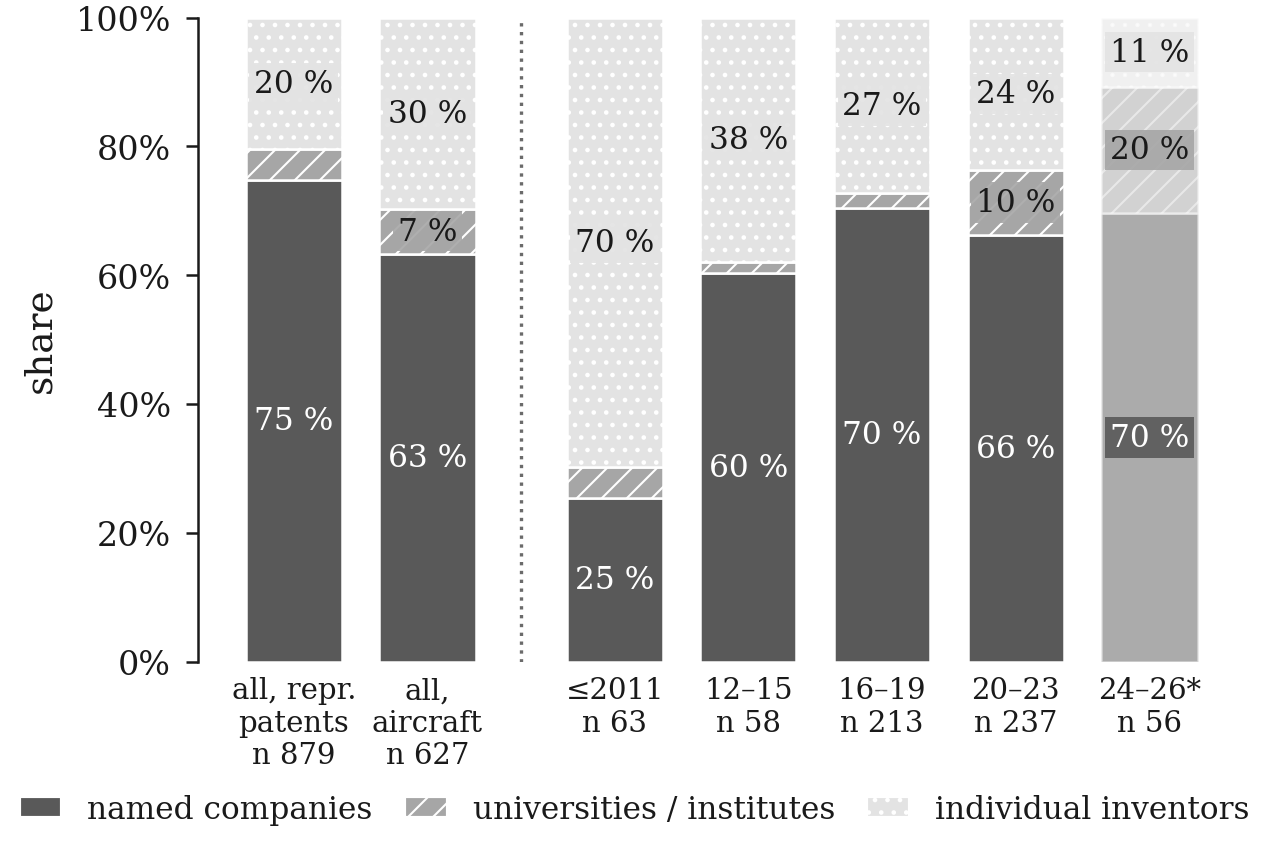

/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V1_who_files/main/q2_filer_types.pdf
 Named company  University / institute  Individual inventor                bar   n
           658                      42                  179 all, repr. patents 879
           397                      44                  186      all, aircraft 627
            16                       3                   44            <= 2011  63
            35                       1                   22            2012-15  58
           150                       5                   58            2016-19 213
           157                      24                   56            2020-23 237
            39                      11                    6  2024-26 (partial)  56


In [2]:
show('q2_filer_types')

### Cumulative share held by the largest assignees

`q2_largest_filers_share` · figure · results

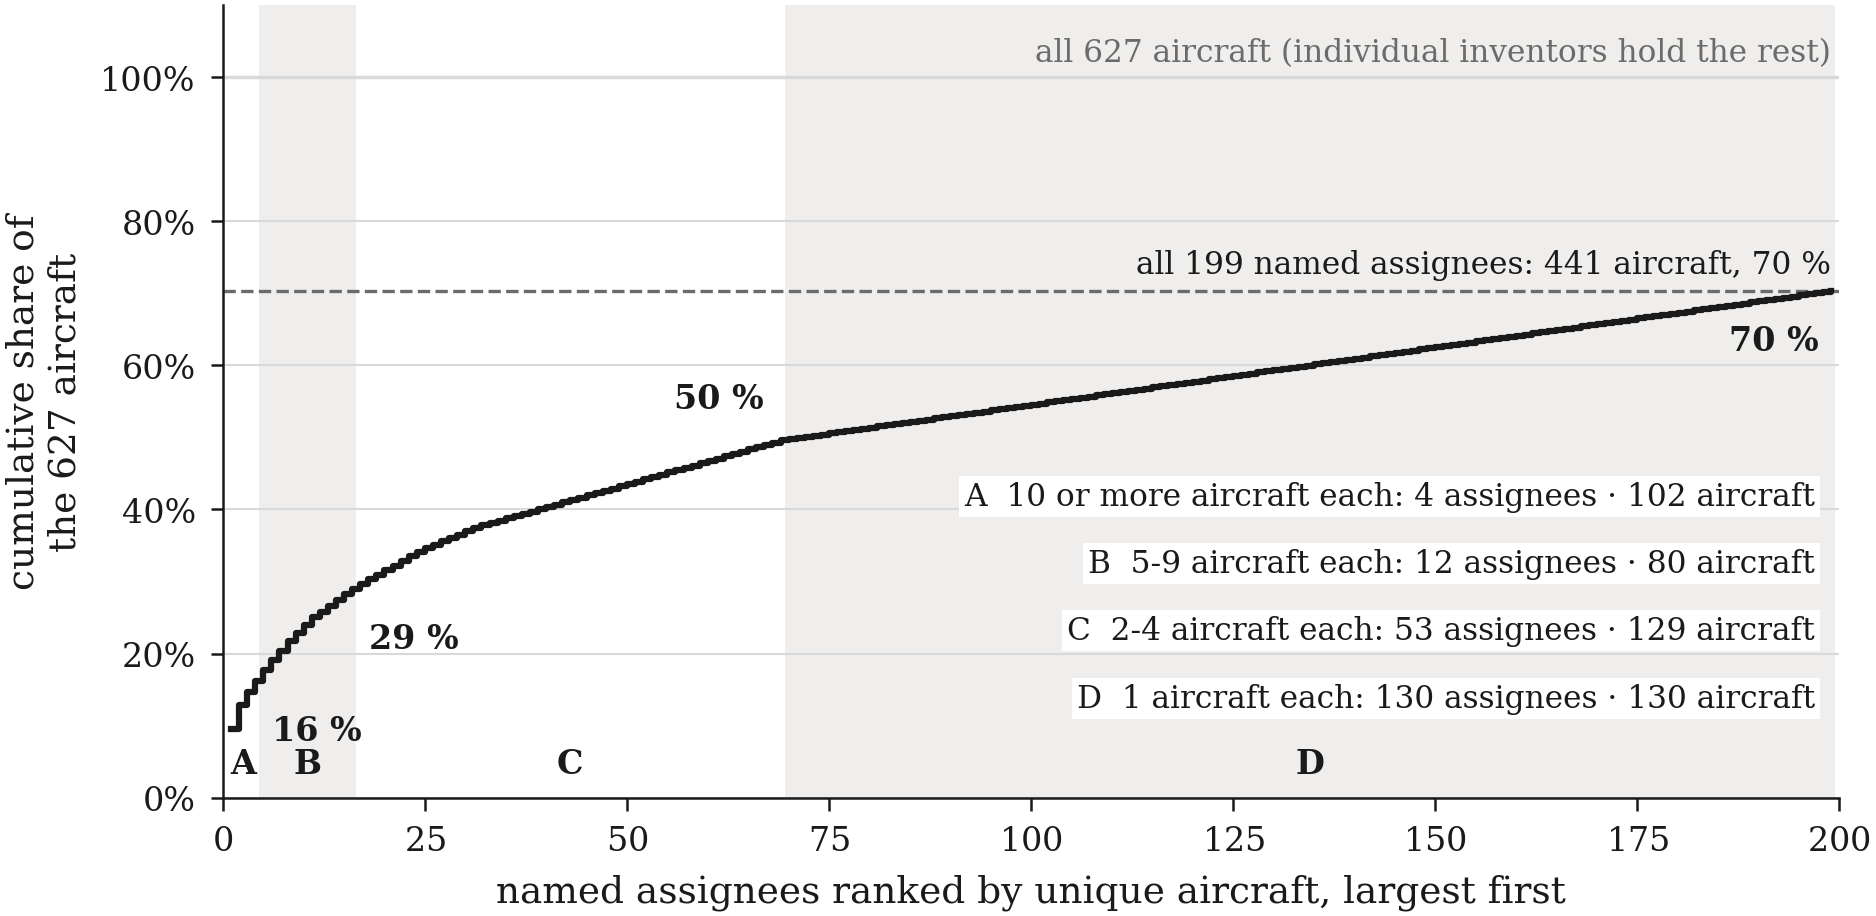

/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V1_who_files/main/q2_largest_filers_share.pdf
 rank               assignee  unique aircraft  cumulative share
    1         Bell / Textron               60             0.096
    2                 Airbus               21             0.129
    3             Kitty Hawk               11             0.147
    4      Shenfeng Aviation               10             0.163
    5                  Honda                9             0.177
    6               Leonardo                9             0.191
    7          Joby Aviation                8             0.204
    8                Porsche                8             0.217
    9 Aurora Flight Sciences                7             0.228
   10                 Lilium                7             0.239
   11                 Boeing                7             

In [3]:
show('q2_largest_filers_share')

### Largest assignee of each architecture

`q2_largest_filer_per_class` · table · results

In [4]:
show('q2_largest_filer_per_class')

/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V1_who_files/main/q2_largest_filer_per_class.csv
            architecture  aircraft  assignees effective assignees largest assignee, all years its share       highest share in one cohort
           Lift + Cruise       165        105                  57                      Airbus       7 %  29 % (one inventor, before 2012)
          Tilt Propulsor       151        100                  25              Bell / Textron      18 % 34 % (Bell / Textron, in 2016-19)
Combined Vectored Thrust       106         67                  24              Bell / Textron      16 % 21 % (Bell / Textron, in 2016-19)
               Tilt Wing        56         43                  25              Bell / Textron      14 % 21 % (Bell / Textron, in 2020-23)
              Multirotor        48         36                  26    

## V.2 New and returning assignees

*Does the pool of assignees renew itself, and do the new ones file different architectures?*

### First-time and returning assignees per cohort

`q2_first_vs_returning_filers` · figure · appendix

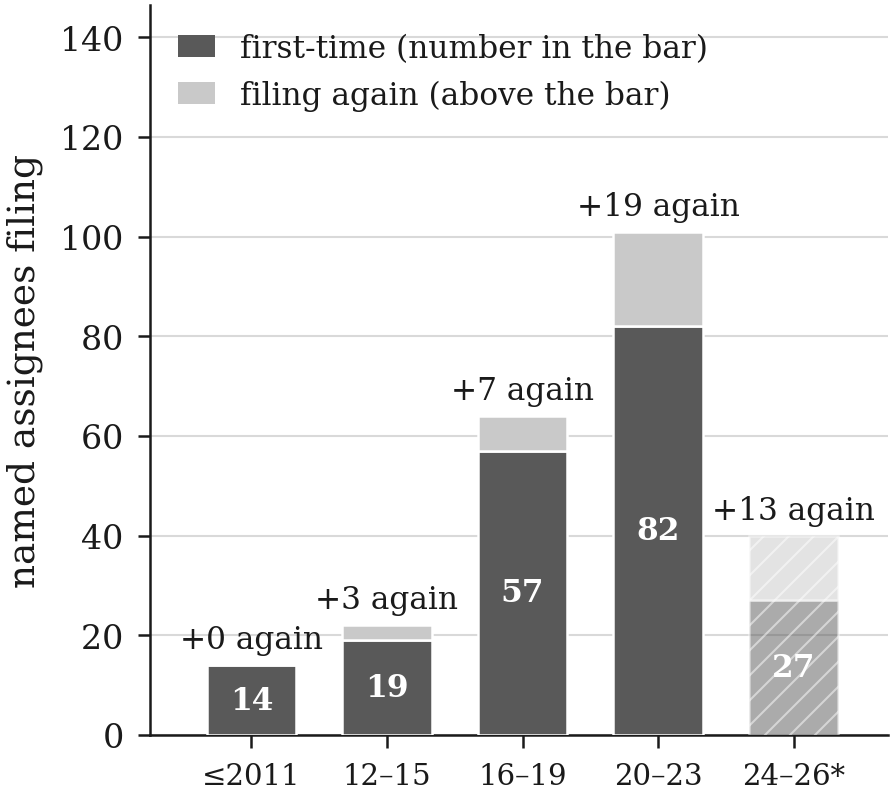

/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V2_new_and_returning_assignees/appendix/q2_first_vs_returning_filers.pdf
           cohort  named assignees active  new assignees  continuing assignees
          <= 2011                      14             14                     0
          2012-15                      22             19                     3
          2016-19                      64             57                     7
          2020-23                     101             82                    19
2024-26 (partial)                      40             27                    13


In [5]:
show('q2_first_vs_returning_filers')

### Architectures of first-time and returning assignees

`q2_entrant_class_mix` · figure · appendix

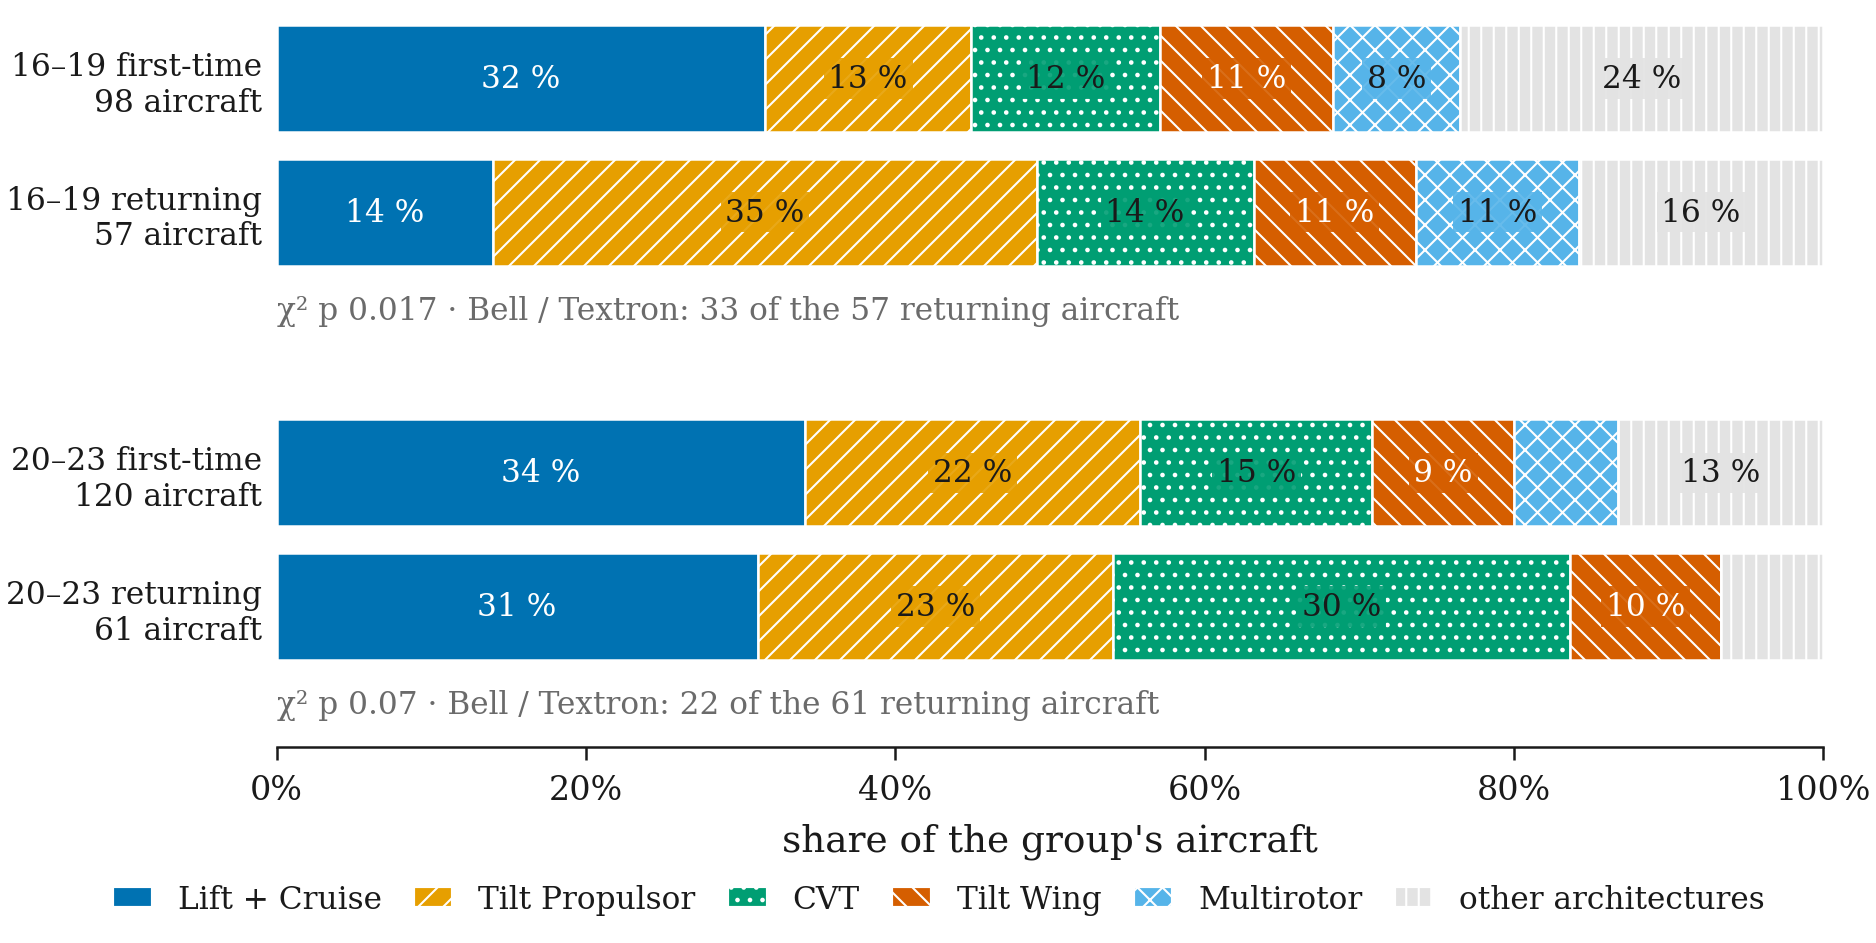

/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V2_new_and_returning_assignees/appendix/q2_entrant_class_mix.pdf
 cohort                group  aircraft  assignees  Lift + Cruise  Tilt Propulsor   CVT  Tilt Wing  Multirotor  other architectures panel  first-time aircraft  returning aircraft  returning assignees     p largest returning assignee  its aircraft  p without it
<= 2011 first-time assignees      19.0       14.0          0.158           0.632 0.053      0.053       0.053                0.053   mix                  NaN                 NaN                  NaN   NaN                        NaN           NaN           NaN
<= 2011  returning assignees       0.0        0.0            NaN             NaN   NaN        NaN         NaN                  NaN   mix                  NaN                 NaN                  NaN   NaN                   

In [6]:
show('q2_entrant_class_mix')

### Tilt Wing among the entering assignees

`q2_tilt_wing_entrants` · figure · appendix

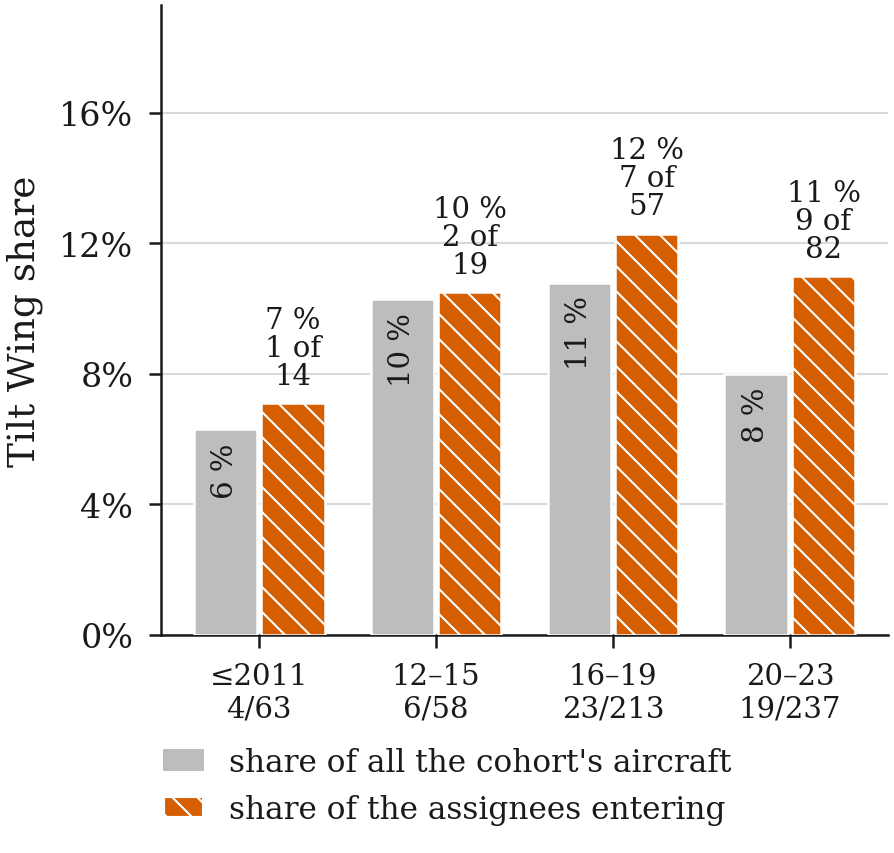

/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V2_new_and_returning_assignees/appendix/q2_tilt_wing_entrants.pdf
 cohort  assignees entering  entering with Tilt Wing  Tilt Wing share of entrants  Tilt Wing entrants: universities / institutes  Tilt Wing entrants: no other aircraft  all entrants: universities / institutes  all entrants: no other aircraft  aircraft in the cohort  Tilt Wing aircraft  Tilt Wing share of the aircraft  Tilt Wing share, Fisher p against the cohort before
<= 2011                  14                        1                        0.071                                              1                                      1                                        2                                6                      63                   4                            0.063                                            NaN     

In [7]:
show('q2_tilt_wing_entrants')

## V.3 What each region files, and when it enters

*Do the regions file different designs, and do they enter each architecture at different times?*

### What each region files, all years

`q3_region_design_all_years` · figure · results

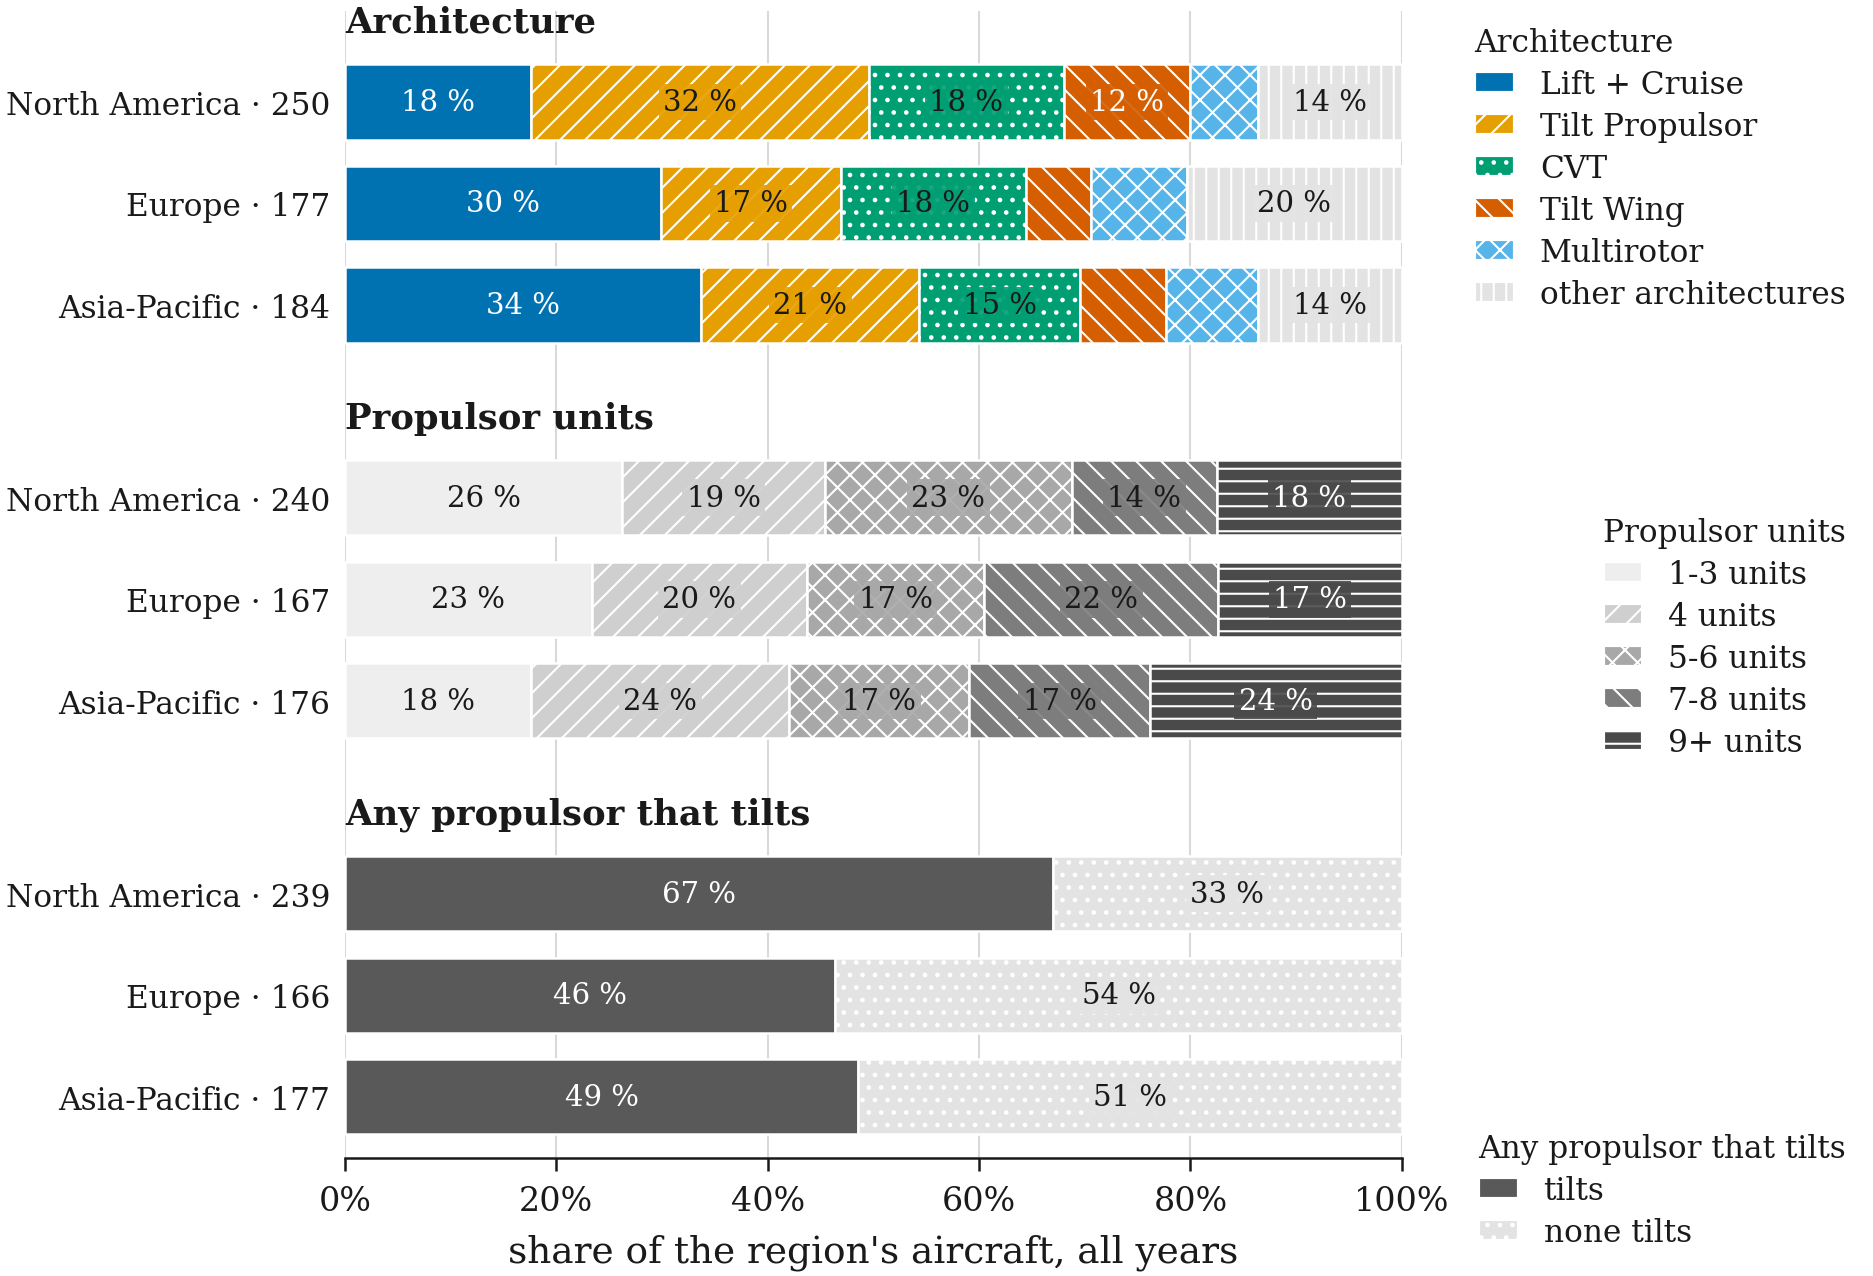

/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V3_regions_what_and_when/main/q3_region_design_all_years.pdf
 SLC   TR  CVT   TW   MR  other        region         variable   n  1-3    4  5-6  7-8   9+  True  False
44.0 80.0 46.0 30.0 16.0   34.0 North America     architecture 250  NaN  NaN  NaN  NaN  NaN   NaN    NaN
53.0 30.0 31.0 11.0 16.0   36.0        Europe     architecture 177  NaN  NaN  NaN  NaN  NaN   NaN    NaN
62.0 38.0 28.0 15.0 16.0   25.0  Asia-Pacific     architecture 184  NaN  NaN  NaN  NaN  NaN   NaN    NaN
 NaN  NaN  NaN  NaN  NaN    NaN North America propulsive units 240 63.0 46.0 56.0 33.0 42.0   NaN    NaN
 NaN  NaN  NaN  NaN  NaN    NaN        Europe propulsive units 167 39.0 34.0 28.0 37.0 29.0   NaN    NaN
 NaN  NaN  NaN  NaN  NaN    NaN  Asia-Pacific propulsive units 176 31.0 43.0 30.0 30.0 42.0   NaN    NaN
 NaN  NaN  N

In [8]:
show('q3_region_design_all_years')

### Architecture per region and cohort

`q3_region_mix_by_window_class` · figure · appendix

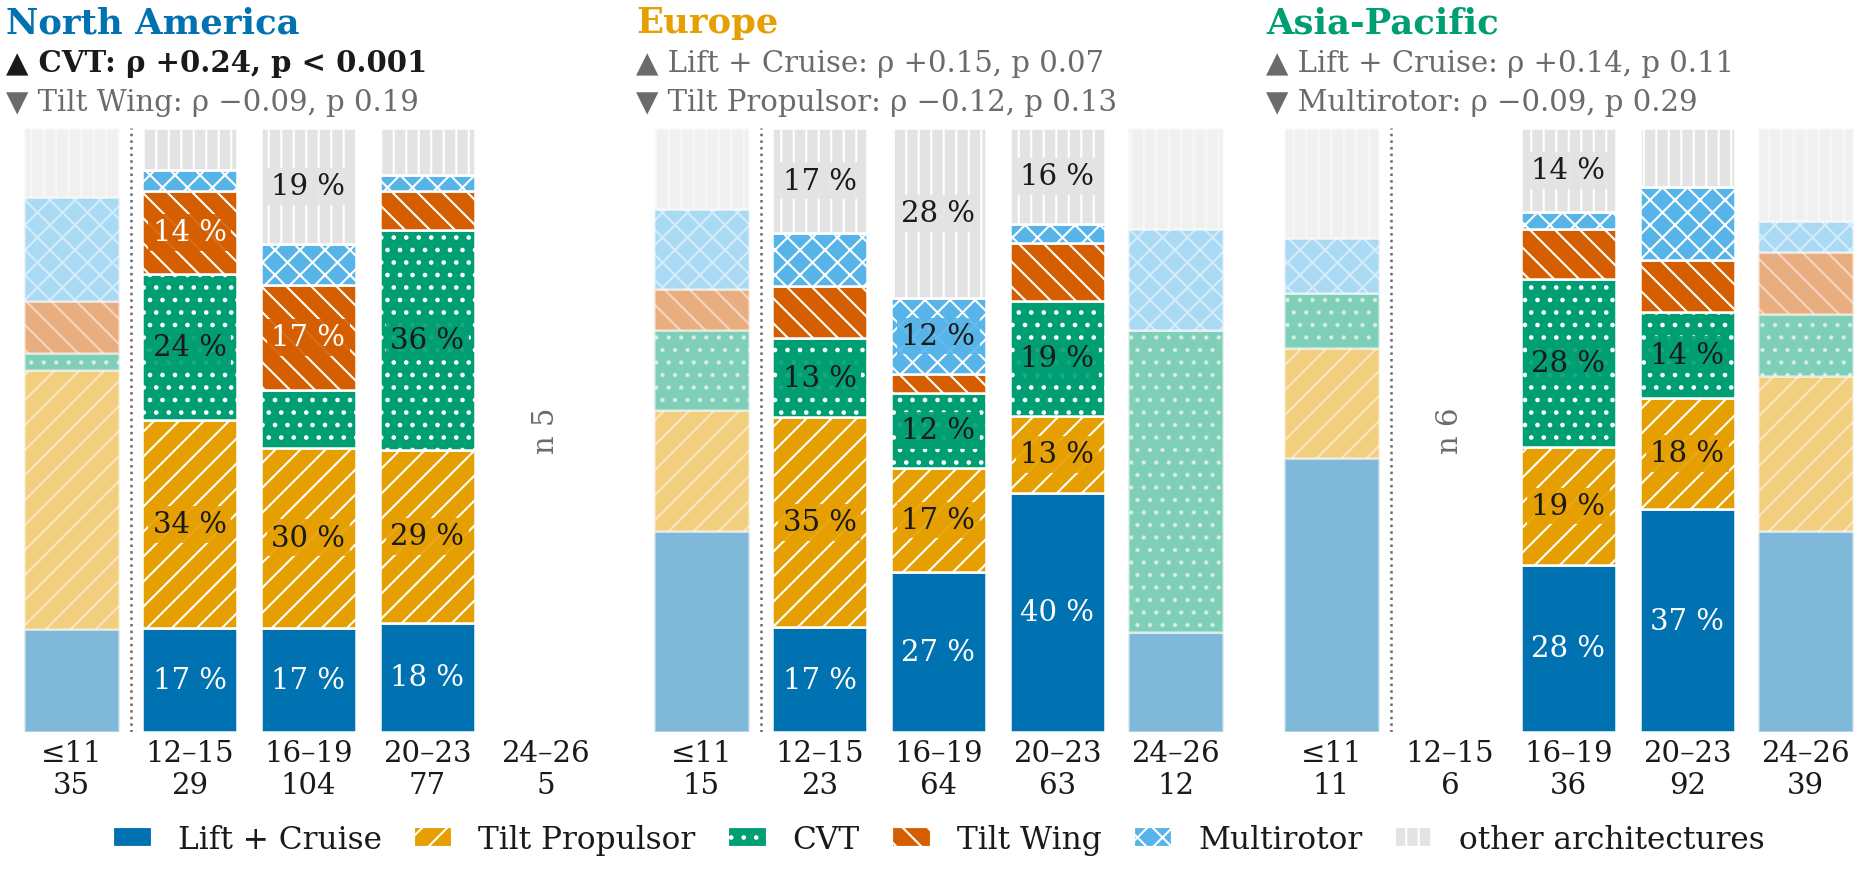

/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V3_regions_what_and_when/appendix/q3_region_mix_by_window_class.pdf
 SLC  TR  CVT  TW  MR  other        region     variable            cohort   n
   6  15    1   3   6      4 North America architecture           <= 2011  35
   5  10    7   4   1      2 North America architecture           2012-15  29
  18  31   10  18   7     20 North America architecture           2016-19 104
  14  22   28   5   2      6 North America architecture           2020-23  77
   0   0    0   0   0      0 North America architecture 2024-26 (partial)   5
   5   3    2   1   2      2        Europe architecture           <= 2011  15
   4   8    3   2   2      4        Europe architecture           2012-15  23
  17  11    8   2   8     18        Europe architecture           2016-19  64
  25   8   12   6   2     10        Eu

In [9]:
show('q3_region_mix_by_window_class')

### Propulsor units per region and cohort

`q3_region_mix_by_window_units` · figure · appendix

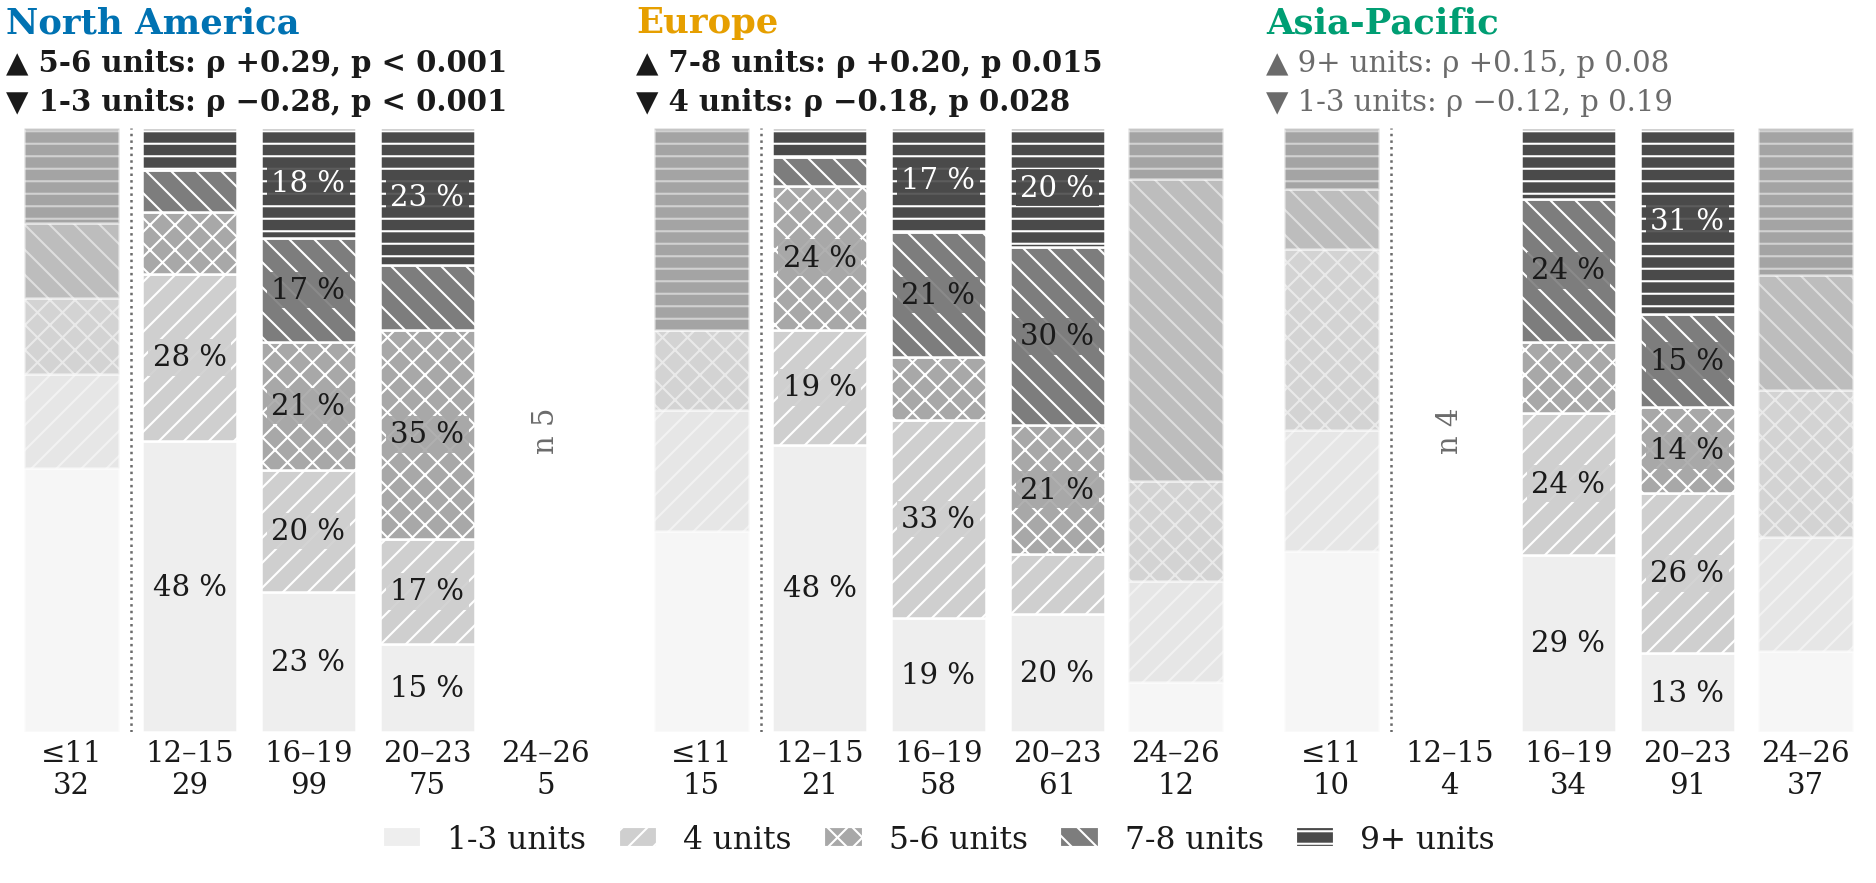

/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V3_regions_what_and_when/appendix/q3_region_mix_by_window_units.pdf
 1-3  4  5-6  7-8  9+        region         variable            cohort  n
  14  5    4    4   5 North America propulsive units           <= 2011 32
  14  8    3    2   2 North America propulsive units           2012-15 29
  23 20   21   17  18 North America propulsive units           2016-19 99
  11 13   26    8  17 North America propulsive units           2020-23 75
   0  0    0    0   0 North America propulsive units 2024-26 (partial)  5
   5  3    2    0   5        Europe propulsive units           <= 2011 15
  10  4    5    1   1        Europe propulsive units           2012-15 21
  11 19    6   12  10        Europe propulsive units           2016-19 58
  12  6   13   18  12        Europe propulsive units           2020-23 61


In [10]:
show('q3_region_mix_by_window_units')

### Tilting share per region and cohort

`q3_region_mix_by_window_tilting` · figure · appendix

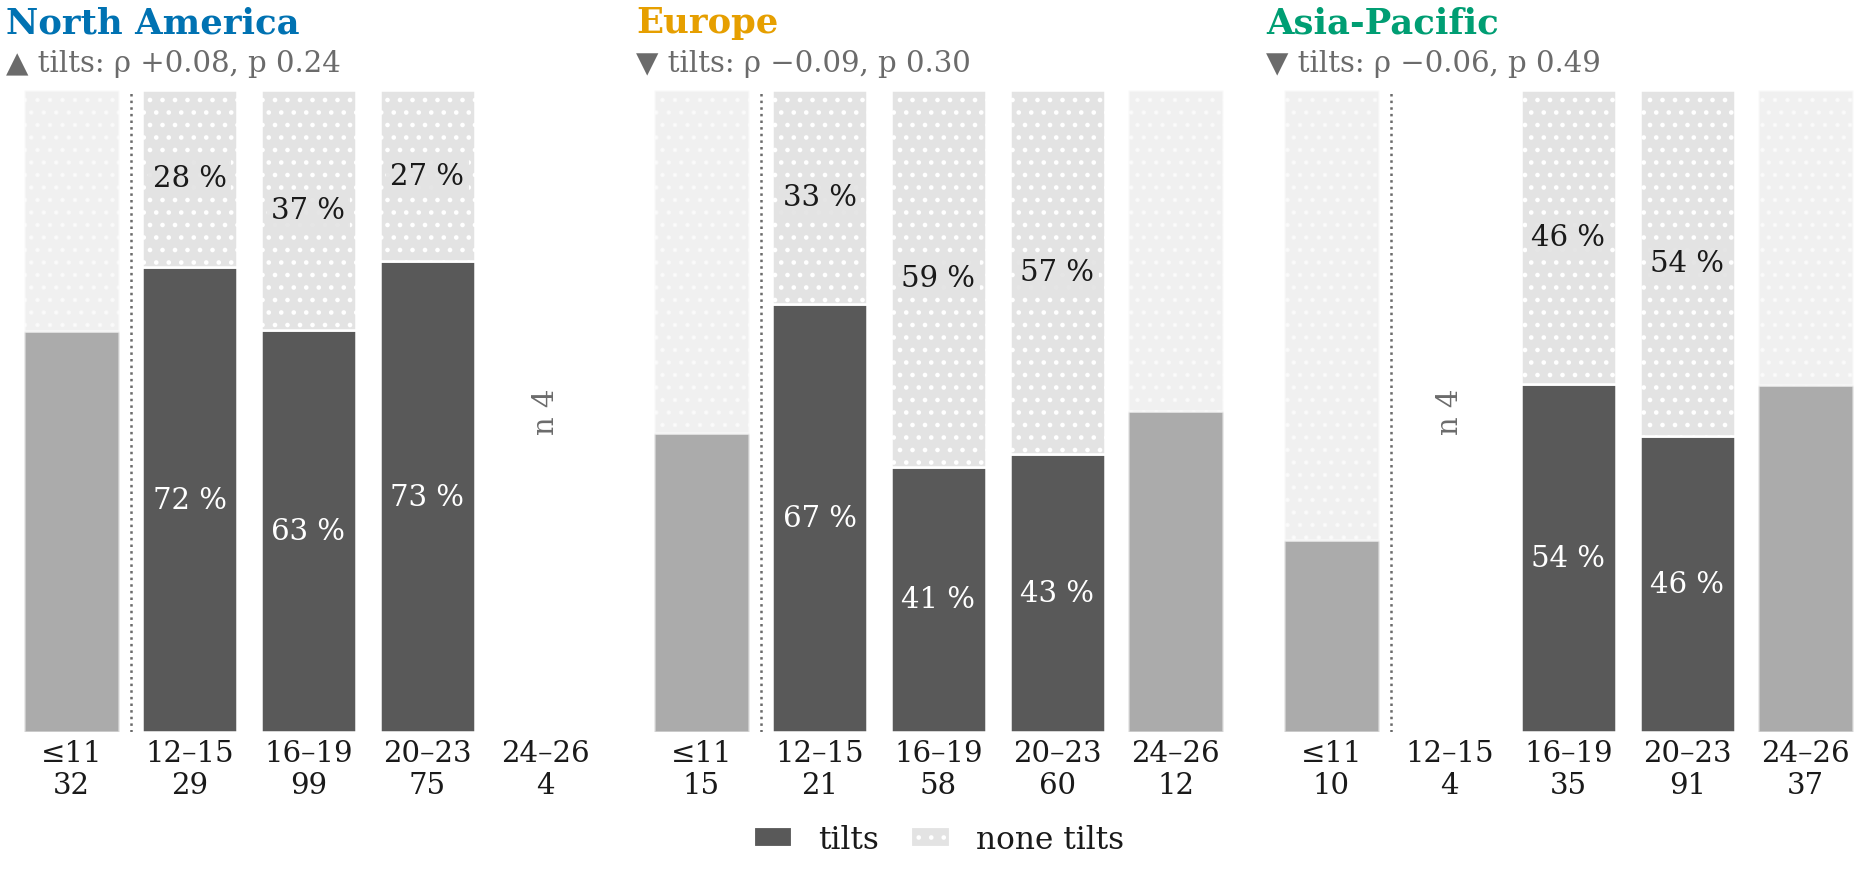

/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V3_regions_what_and_when/appendix/q3_region_mix_by_window_tilting.pdf
 True  False        region     variable            cohort  n
   20     12 North America tilting unit           <= 2011 32
   21      8 North America tilting unit           2012-15 29
   62     37 North America tilting unit           2016-19 99
   55     20 North America tilting unit           2020-23 75
    0      0 North America tilting unit 2024-26 (partial)  4
    7      8        Europe tilting unit           <= 2011 15
   14      7        Europe tilting unit           2012-15 21
   24     34        Europe tilting unit           2016-19 58
   26     34        Europe tilting unit           2020-23 60
    6      6        Europe tilting unit 2024-26 (partial) 12
    3      7  Asia-Pacific tilting unit           <= 2011 10
    0 

In [11]:
show('q3_region_mix_by_window_tilting')

### Years after North America, per architecture

`q3_region_entry_lag` · figure · results

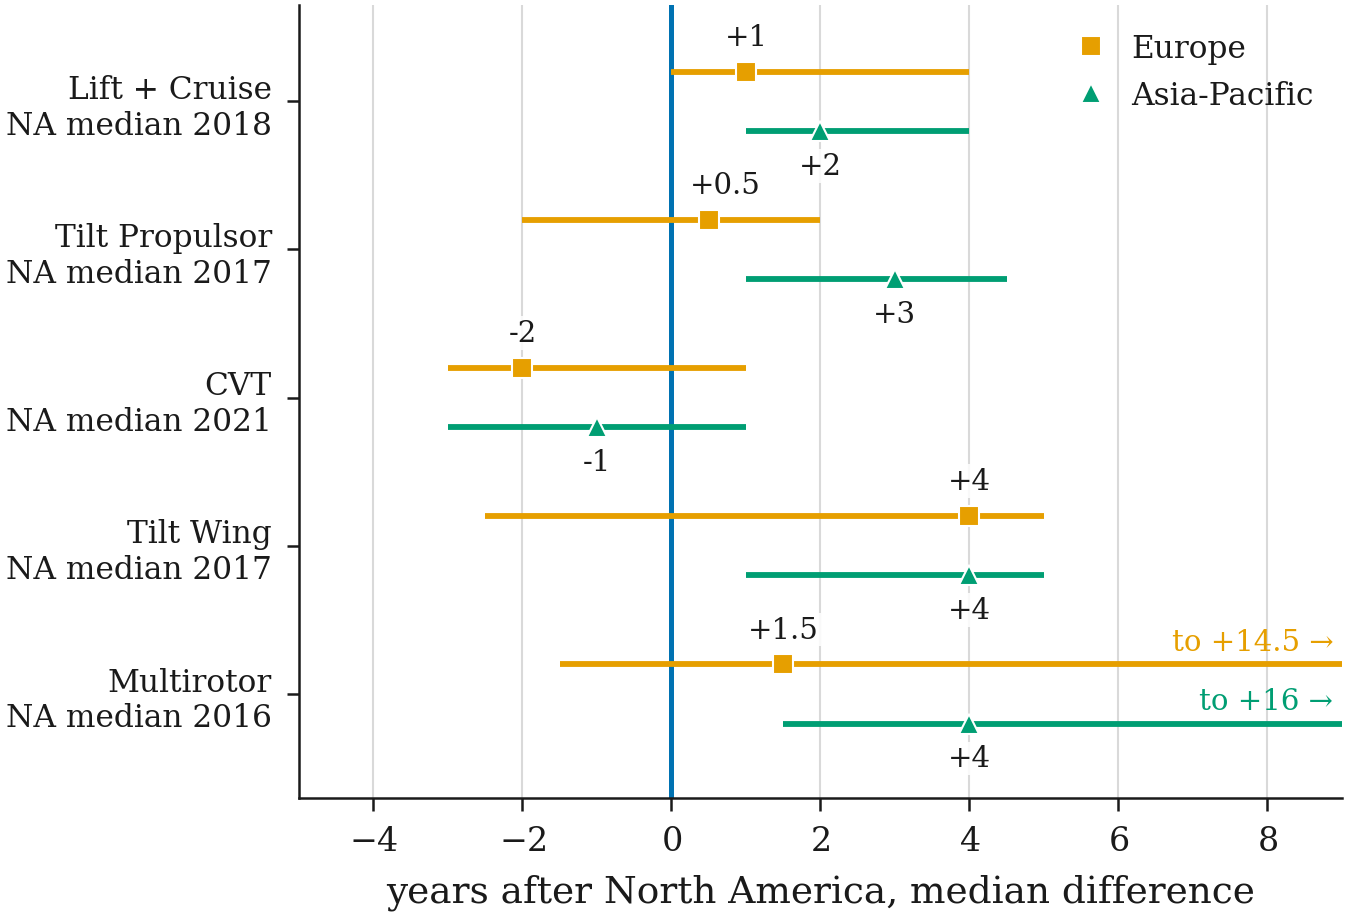

/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V3_regions_what_and_when/main/q3_region_entry_lag.pdf
            architecture        region  aircraft  median priority year  offset vs North America (years)  95 % low  95 % high
Combined vectored thrust North America        46                2021.0                              0.0      -2.0        1.5
Combined vectored thrust        Europe        25                2019.0                             -2.0      -3.0        1.0
Combined vectored thrust  Asia-Pacific        24                2020.0                             -1.0      -3.0        1.0
           Lift + Cruise North America        43                2018.0                              0.0      -2.0        2.0
           Lift + Cruise        Europe        51                2019.0                              1.0       0.0        4.0
    

In [12]:
show('q3_region_entry_lag')

### The applicant countries behind the regions

`q3_region_countries` · figure · appendix

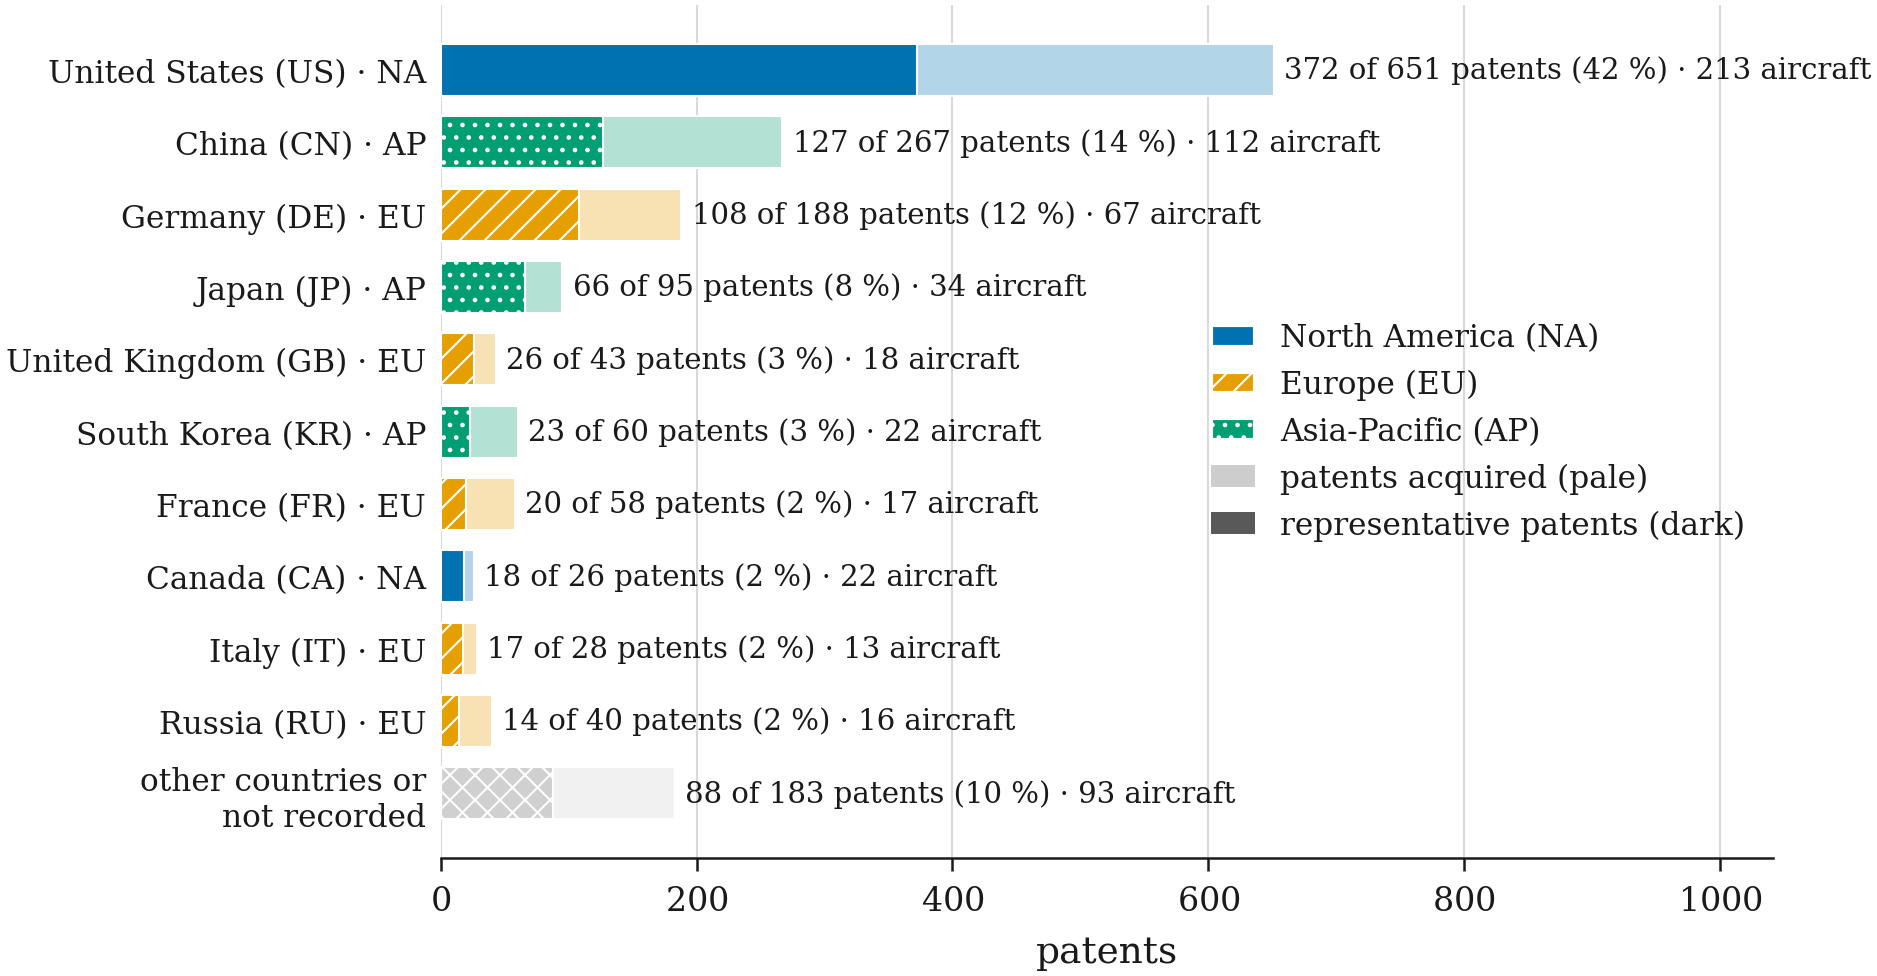

/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V3_regions_what_and_when/appendix/q3_region_countries.pdf
              country        region  patents acquired  representative patents  unique aircraft  share of representative patents  share of unique aircraft
                   US North America               651                     372              213                            0.423                     0.340
                   CN  Asia-Pacific               267                     127              112                            0.144                     0.179
                   DE        Europe               188                     108               67                            0.123                     0.107
                   JP  Asia-Pacific                95                      66               34                            0.075       

In [13]:
show('q3_region_countries')

## V.4 The regions and the tilting family F

*Does the share of F, or the tilting lean, differ between the regions?*

### Family F share per region and cohort

`q7_region_family_share` · figure · results

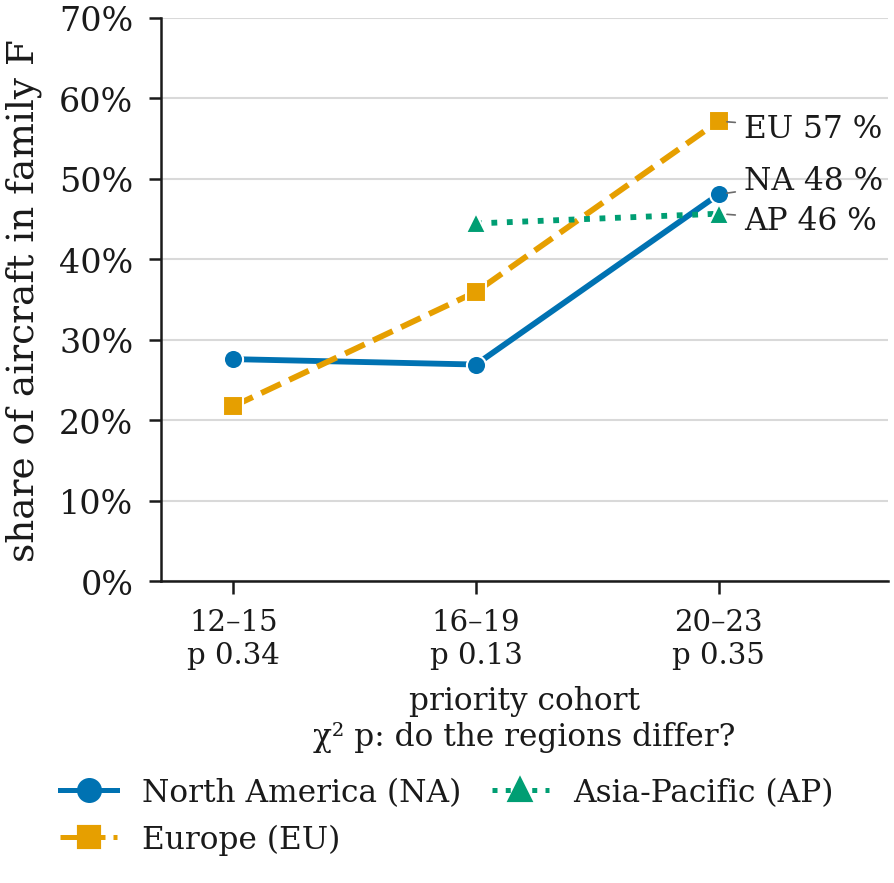

/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V4_regions_and_family_F/main/q7_region_family_share.pdf
       region  F aircraft 2012-15  F base 2012-15  F share 2012-15  F aircraft 2016-19  F base 2016-19  F share 2016-19  F aircraft 2020-23  F base 2020-23  F share 2020-23
North America                   8              29            0.276                  28             104            0.269                  37              77            0.480
       Europe                   5              23            0.217                  23              64            0.359                  36              63            0.571
 Asia-Pacific                   0               6            0.000                  16              36            0.444                  42              92            0.456


In [14]:
show('q7_region_family_share')

### Tilting lean with and without the largest assignee

`q7_region_lean_without_largest_filer` · figure · appendix

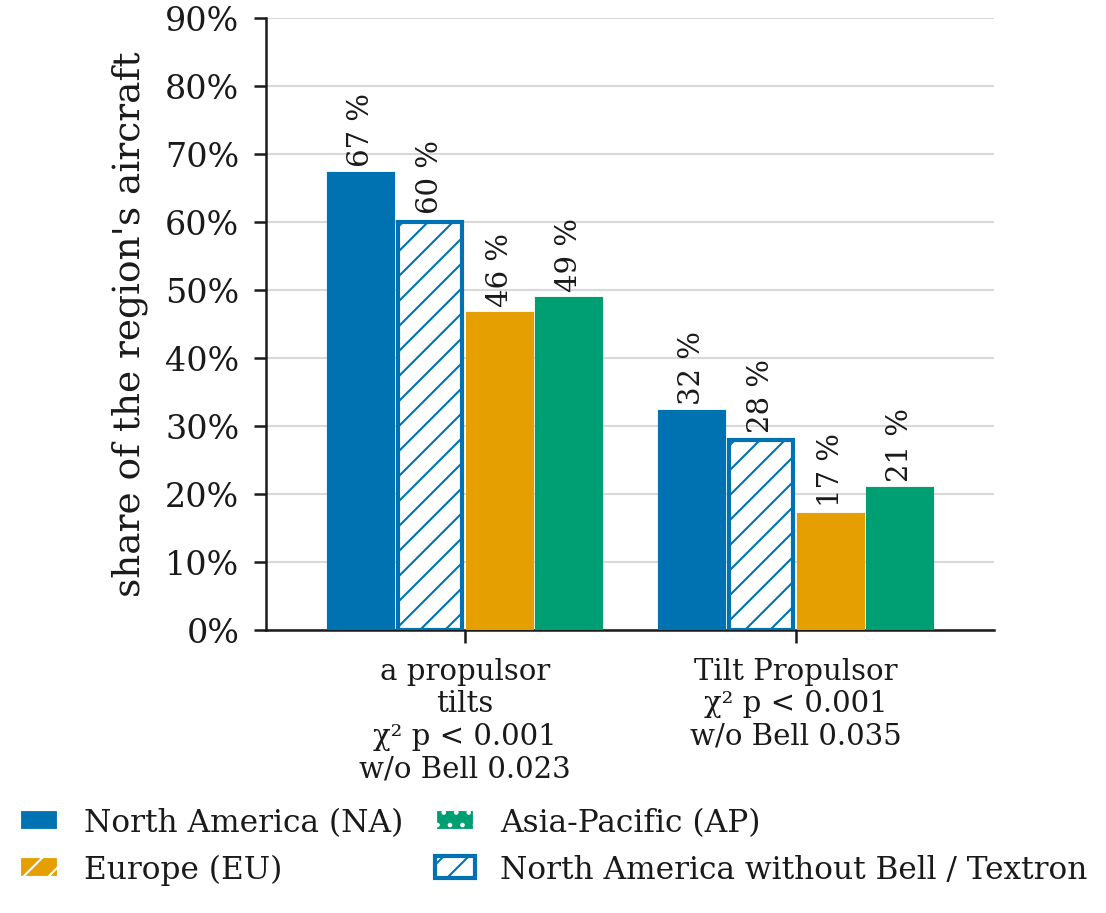

/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V4_regions_and_family_F/appendix/q7_region_lean_without_largest_filer.pdf
       region  aircraft  largest assignee  its aircraft  its Tilt Propulsor aircraft  Tilt Propulsor aircraft  tilting share  tilting share without it  Tilt Propulsor share  Tilt Propulsor share without it
North America       250    Bell / Textron            60                           27                       80          0.670                     0.600                 0.320                            0.279
       Europe       177            Airbus            20                            0                       30          0.464                     0.507                 0.170                            0.191
 Asia-Pacific       186 Shenfeng Aviation            10                            0                       38       

In [15]:
show('q7_region_lean_without_largest_filer')

## Numbers for the text

In [16]:
n = a5.numbers_for_text(ctx)
a5.print_numbers(n)

1. Share of designs per region (all aircraft of the cohort in the denominator)
           cohort  designs North America Europe Asia-Pacific others sum of the three
        all years      627        39.9 % 28.2 %       29.7 %  2.2 %           97.8 %
          2012-15       58        50.0 % 39.7 %       10.3 %  0.0 %          100.0 %
          2016-19      213        48.8 % 30.0 %       17.8 %  3.3 %           96.7 %
          2020-23      237        32.5 % 26.6 %       38.8 %  2.1 %           97.9 %
2024-26 (partial)       56         8.9 % 21.4 %       69.6 %  0.0 %          100.0 %

2. Entry lag, median priority-year offset from North America, 95 % bootstrap interval
   priority years             architecture       region  aircraft  offset vs North America (years)                    interval touches or includes 0
all years to 2023 Combined vectored thrust       Europe        25                             -2.0                -3.0 to +1.0                   YES
all years to 2023 Combined